# Lab 2 - Malware Detection (API CALLS)
Compare BoW, FFNN, RNN and GNN for malware classification from API call sequences.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


train_data = pd.read_json("train.json")
test_data = pd.read_json("test.json")

print("Training samples:", len(train_data))
print("Test samples:", len(test_data))

#train_data.head()
#test_data.head()

print("Label:", train_data.loc[0, "is_malware"])
print("First 10 API calls:", train_data.loc[0, "api_call_sequence"][:10])

Training samples: 16325
Test samples: 6505
Label: 1
First 10 API calls: ['LdrGetDllHandle', 'LdrGetProcedureAddress', 'LdrLoadDll', 'LdrGetProcedureAddress', 'LdrGetDllHandle', 'LdrGetProcedureAddress', 'GetTimeZoneInformation', 'LoadStringW', 'RegOpenKeyExW', 'RegQueryValueExW']


# Task1 - Analytics
Evaluating class distributions and other info

Training class counts:
is_malware
1    15714
0      611
Name: count, dtype: int64

Training class percentages:
is_malware
1    96.257274
0     3.742726
Name: proportion, dtype: float64

Test class counts:
is_malware
1    6262
0     243
Name: count, dtype: int64

Test class percentages:
is_malware
1    96.264412
0     3.735588
Name: proportion, dtype: float64
              Train         Test
count  16325.000000  6505.000000
mean      75.030812    86.331130
std        8.951411     9.113511
min       60.000000    70.000000
25%       67.000000    79.000000
50%       75.000000    87.000000
75%       83.000000    94.000000
max       90.000000   100.000000
              train         test
count  16325.000000  6505.000000
mean      75.030812    86.331130
std        8.951411     9.113511
min       60.000000    70.000000
25%       67.000000    79.000000
50%       75.000000    87.000000
75%       83.000000    94.000000
max       90.000000   100.000000


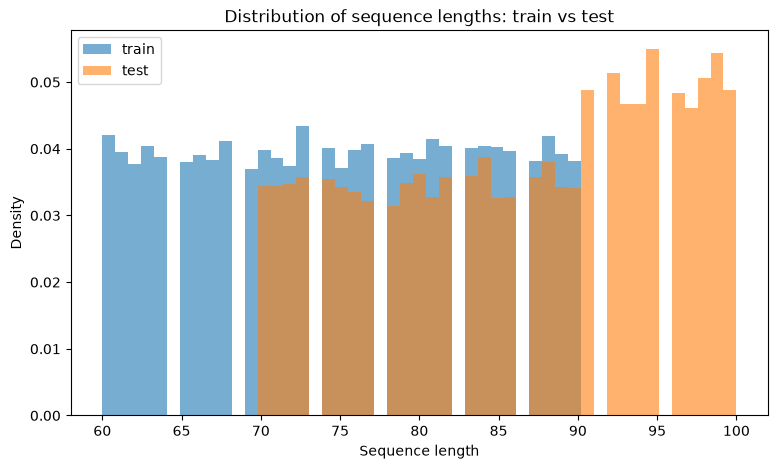

In [3]:

# Some info regarding the different class 
print("Training class counts:")
print(train_data["is_malware"].value_counts())

print("\nTraining class percentages:")# in percentuali 
print(train_data["is_malware"].value_counts(normalize=True).mul(100))

print("\nTest class counts:")
print(test_data["is_malware"].value_counts())

print("\nTest class percentages:")
print(test_data["is_malware"].value_counts(normalize=True).mul(100))

#max lenght of api_call_sequence

train_data["sequence_length"] = train_data["api_call_sequence"].apply(len)
test_data["sequence_length"] = test_data["api_call_sequence"].apply(len)

length_summary = pd.DataFrame({
    "Train": train_data["sequence_length"].describe(),
    "Test": test_data["sequence_length"].describe()
})

print(length_summary)

train_len = train_data["api_call_sequence"].apply(len)
test_len = test_data["api_call_sequence"].apply(len)

# Statistiche per confrontarli numericamente
print(pd.DataFrame({"train": train_len.describe(), "test": test_len.describe()}))

# Istogrammi con bin condivisi e density=True (train e test hanno dimensioni diverse)
bins = np.linspace(min(train_len.min(), test_len.min()),
                   max(train_len.max(), test_len.max()), 50)

plt.figure(figsize=(9, 5))
plt.hist(train_len, bins=bins, alpha=0.6, density=True, label="train")
plt.hist(test_len, bins=bins, alpha=0.6, density=True, label="test")
plt.xlabel("Sequence length")
plt.ylabel("Density")
plt.title("Distribution of sequence lengths: train vs test")
plt.legend()
plt.show()


## Train split & validation + Vocabulary


In [4]:
from sklearn.model_selection import train_test_split # type: ignore

train_split, val_split = train_test_split(
    train_data,
    test_size=0.2,
    stratify=train_data["is_malware"],
    random_state=42
)

print("Training samples:", len(train_split))
print("Validation samples:", len(val_split))

Training samples: 13060
Validation samples: 3265


In [5]:
# Vocabulary size

train_vocab = set()

for sequence in train_split["api_call_sequence"]:
    for call in sequence:
        train_vocab.add(call)

print("Vocabulary size:", len(train_vocab))

# Test one
test_vocab = set()

for sequence in test_data["api_call_sequence"]:
    for call in sequence:
        test_vocab.add(call)

unseen_calls = test_vocab - train_vocab

print("Distinct unseen test calls:", len(unseen_calls))
print("Unseen calls:", sorted(unseen_calls))

# Calcolo unseen calls per sample in the test set
samples_with_unseen = 0

for sequence in test_data["api_call_sequence"]:
    for call in sequence:
        if call not in train_vocab:
            samples_with_unseen += 1
            break

print("Test samples with unseen calls:", samples_with_unseen)

Vocabulary size: 256
Distinct unseen test calls: 3
Unseen calls: ['ControlService', 'NtDeleteKey', 'WSASocketA']
Test samples with unseen calls: 3


## Task 2 - Bag-of-Words
Compare Standard and Weighted on validation. Freeze one model per representation, then evaluate original and shuffled TEST sequences without retraining.

### Shared setup
Same split, seed, architecture, learning rate, batch size and epochs. Only class weighting changes.

In [6]:
import random
from time import perf_counter
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score

SEED, EPOCHS, BATCH_SIZE = 42, 20, 64
LEARNING_RATE, THRESHOLD = 0.001, 0.5
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
variants = [("Standard", False), ("Weighted", True)]

def identity(sequence):
    return sequence

print("Device:", device)


Device: cpu


### Shared classifier and training
The same FFNN and training loop serve 2A and 2B. Time covers training only. No files are created by notebook code.

In [7]:
class BoWFFNN(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_size, 64), nn.ReLU(),
            nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(1)


def train_variant(X_train_t, y_train_t, use_weights):
    # Same initial weights and batch order for both variants.
    torch.manual_seed(SEED)
    generator = torch.Generator().manual_seed(SEED)
    model = BoWFFNN(X_train_t.shape[1]).to(device)
    loader = DataLoader(
        TensorDataset(X_train_t, y_train_t), batch_size=BATCH_SIZE,
        shuffle=True, generator=generator,
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loss_fn = nn.BCEWithLogitsLoss(reduction="none")

    # Class weights use training labels only: 0 = goodware, 1 = malware.
    weights = torch.ones(2, device=device)
    if use_weights:
        n_goodware = int((y_train_t == 0).sum())
        n_malware = int((y_train_t == 1).sum())
        weights = torch.tensor(
            [len(y_train_t) / (2 * n_goodware), len(y_train_t) / (2 * n_malware)],
            dtype=torch.float32, device=device,
        )

    model.train()
    if device.type == "cuda":
        torch.cuda.synchronize()
    start = perf_counter()
    for _ in range(EPOCHS):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = (loss_fn(model(xb), yb) * weights[yb.long()]).mean()
            loss.backward()
            optimizer.step()
    if device.type == "cuda":
        torch.cuda.synchronize()
    return model, perf_counter() - start


def predict_labels(model, X):
    model.eval()
    with torch.no_grad():
        probabilities = torch.sigmoid(model(X))
    return (probabilities > THRESHOLD).int().cpu().numpy()


### Task 2A - Unigram BoW
Count single API calls, compare the two variants on validation and keep the better one.

Unigram features: 256
Training: Standard
Training: Weighted


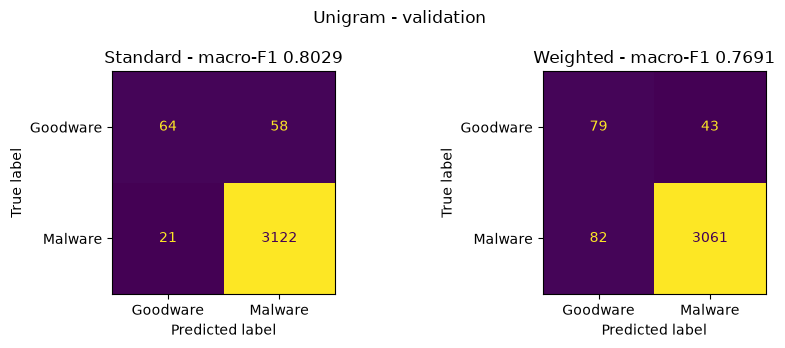

 Variant  Macro-F1  Goodware recall  Malware recall  Train s
Standard    0.8029           0.5246          0.9933   9.9706
Weighted    0.7691           0.6475          0.9739   9.1849
SELECTED Unigram: Standard


In [8]:
# 1. Count APIs: learn the vocabulary on training only.
vectorizer_uni = CountVectorizer(
    tokenizer=identity,
    token_pattern=None,
    lowercase=False,
    ngram_range=(1, 1),
)
X_train = vectorizer_uni.fit_transform(train_split["api_call_sequence"]).toarray()
X_val = vectorizer_uni.transform(val_split["api_call_sequence"]).toarray()

# 2. Compress large counts, then scale using TRAINING statistics only.
X_train = np.log1p(X_train)
X_val = np.log1p(X_val)
scaler_uni = StandardScaler()
X_train = scaler_uni.fit_transform(X_train)
X_val = scaler_uni.transform(X_val)

# 3. Labels stay separate. PyTorch needs float32 input tensors.
y_train = train_split["is_malware"].to_numpy()
y_val = val_split["is_malware"].to_numpy()
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_val_t = torch.tensor(X_val, dtype=torch.float32, device=device)
print("Unigram features:", X_train.shape[1])

# 4. Compare Standard and Weighted with the SAME data and settings.
models_uni = {}
validation_rows = []
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))

for index, (name, use_weights) in enumerate(variants):
    print("Training:", name)
    model, seconds = train_variant(X_train_t, y_train_t, use_weights)

    predictions = predict_labels(model, X_val_t)

    report = classification_report(y_val, predictions, output_dict=True, zero_division=0)
    macro_f1 = report["macro avg"]["f1-score"]
    goodware_recall = report["0"]["recall"]
    malware_recall = report["1"]["recall"]

    models_uni[name] = model
    validation_rows.append({
        "Variant": name,
        "Macro-F1": macro_f1,
        "Goodware recall": goodware_recall,
        "Malware recall": malware_recall,
        "Train s": seconds,
    })

    ConfusionMatrixDisplay.from_predictions(
        y_val, predictions, labels=[0, 1],
        display_labels=["Goodware", "Malware"], ax=axes[index], colorbar=False,
    )
    axes[index].set_title(f"{name} - macro-F1 {macro_f1:.4f}")

fig.suptitle("Unigram - validation")
plt.tight_layout()
plt.show()

# 5. Keep the variant with the highest VALIDATION macro-F1.
results_uni = pd.DataFrame(validation_rows)
best_uni = results_uni.loc[results_uni["Macro-F1"].idxmax()]
model_uni = models_uni[best_uni["Variant"]]
print(results_uni.round(4).to_string(index=False))
print("SELECTED Unigram:", best_uni["Variant"])


### Task 2B - Unigrams + bigrams
Repeat the same steps with adjacent API pairs. Use the same train_split and val_split.

Unigram + bigram features: 5741
Training: Standard
Training: Weighted


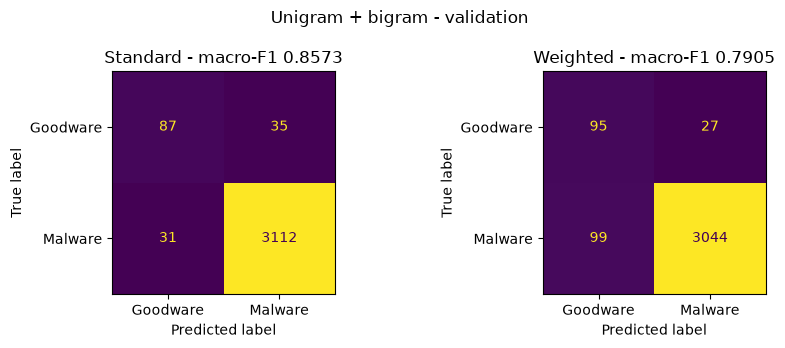

 Variant  Macro-F1  Goodware recall  Malware recall  Train s
Standard    0.8573           0.7131          0.9901  16.7869
Weighted    0.7905           0.7787          0.9685  19.9400
SELECTED Unigram + bigram: Standard


In [9]:
# 1. Count APIs: learn the vocabulary on training only.
vectorizer_bi = CountVectorizer(
    tokenizer=identity,
    token_pattern=None,
    lowercase=False,
    ngram_range=(1, 2),
)
X_train = vectorizer_bi.fit_transform(train_split["api_call_sequence"]).toarray()
X_val = vectorizer_bi.transform(val_split["api_call_sequence"]).toarray()

# 2. Compress large counts, then scale using TRAINING statistics only.
X_train = np.log1p(X_train)
X_val = np.log1p(X_val)
scaler_bi = StandardScaler()
X_train = scaler_bi.fit_transform(X_train)
X_val = scaler_bi.transform(X_val)

# 3. Labels stay separate. PyTorch needs float32 input tensors.
y_train = train_split["is_malware"].to_numpy()
y_val = val_split["is_malware"].to_numpy()
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_val_t = torch.tensor(X_val, dtype=torch.float32, device=device)
print("Unigram + bigram features:", X_train.shape[1])

# 4. Compare Standard and Weighted with the SAME data and settings.
models_bi = {}
validation_rows = []
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))

for index, (name, use_weights) in enumerate(variants):
    print("Training:", name)
    model, seconds = train_variant(X_train_t, y_train_t, use_weights)

    predictions = predict_labels(model, X_val_t)

    report = classification_report(y_val, predictions, output_dict=True, zero_division=0)
    macro_f1 = report["macro avg"]["f1-score"]
    goodware_recall = report["0"]["recall"]
    malware_recall = report["1"]["recall"]

    models_bi[name] = model
    validation_rows.append({
        "Variant": name,
        "Macro-F1": macro_f1,
        "Goodware recall": goodware_recall,
        "Malware recall": malware_recall,
        "Train s": seconds,
    })

    ConfusionMatrixDisplay.from_predictions(
        y_val, predictions, labels=[0, 1],
        display_labels=["Goodware", "Malware"], ax=axes[index], colorbar=False,
    )
    axes[index].set_title(f"{name} - macro-F1 {macro_f1:.4f}")

fig.suptitle("Unigram + bigram - validation")
plt.tight_layout()
plt.show()

# 5. Keep the variant with the highest VALIDATION macro-F1.
results_bi = pd.DataFrame(validation_rows)
best_bi = results_bi.loc[results_bi["Macro-F1"].idxmax()]
model_bi = models_bi[best_bi["Variant"]]
print(results_bi.round(4).to_string(index=False))
print("SELECTED Unigram + bigram:", best_bi["Variant"])


### Test - original and shuffled
Evaluate the best unigram and bigram variants already selected in 2A/2B. No retraining.

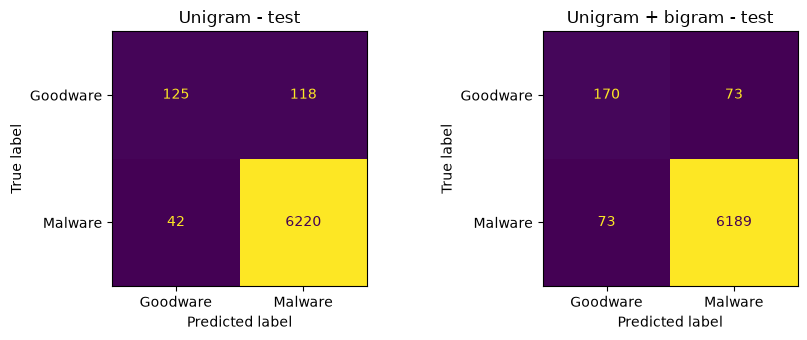

           Model  Test macro-F1  Shuffled macro-F1  Changed predictions
         Unigram         0.7985             0.7985                    0
Unigram + bigram         0.8440             0.5185                  390


In [10]:
# Shuffle each sequence without changing its calls or label.
rng = random.Random(SEED)
test_shuffled = []
for sequence in test_data["api_call_sequence"]:
    shuffled = sequence.copy()
    rng.shuffle(shuffled)
    test_shuffled.append(shuffled)
y_test = test_data["is_malware"].to_numpy()


def predict_test(model, vectorizer, scaler, sequences):
    X = vectorizer.transform(sequences).toarray()
    X = scaler.transform(np.log1p(X))
    X = torch.tensor(X, dtype=torch.float32, device=device)
    return predict_labels(model, X)


selected_models = [
    ("Unigram", model_uni, vectorizer_uni, scaler_uni),
    ("Unigram + bigram", model_bi, vectorizer_bi, scaler_bi),
]
rows = []
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, (name, model, vectorizer, scaler) in zip(axes, selected_models):
    original = predict_test(model, vectorizer, scaler, test_data["api_call_sequence"])
    shuffled = predict_test(model, vectorizer, scaler, test_shuffled)
    rows.append({
        "Model": name,
        "Test macro-F1": f1_score(y_test, original, average="macro"),
        "Shuffled macro-F1": f1_score(y_test, shuffled, average="macro"),
        "Changed predictions": int((original != shuffled).sum()),
    })
    ConfusionMatrixDisplay.from_predictions(
        y_test, original, labels=[0, 1], display_labels=["Goodware", "Malware"],
        ax=ax, colorbar=False,
    )
    ax.set_title(name + " - test")
plt.tight_layout()
plt.show()
test_results = pd.DataFrame(rows)
print(test_results.round(4).to_string(index=False))


## Task 3
Compare integer IDs and learnable embeddings.

In [ ]:
# we already have the various split is useless to do it again, 
# but here is how to do it if you want to split the training 
# set into train and validation sets

# So now we have a MAP for all the api calls (Integers ID)

# Reserved IDs
PAD = 0
UNK = 1

# Choose the length(90 in train as already evaluated) using training data only
MAX_LEN = int(train_split["api_call_sequence"].apply(len).max())

# Reuse the vocabulary built from train_split
vocab = {}
for api_id, api in enumerate(sorted(train_vocab), start=2):
    vocab[api] = api_id

VOCAB_SIZE = len(vocab) + 2

print("Sequence length:", MAX_LEN)
print("Distinct APIs:", len(vocab))
print("Total IDs including PAD and UNK:", VOCAB_SIZE)
print("Mapping examples:", list(vocab.items())[:5])

Sequence length: 90
Distinct APIs: 256
Total IDs including PAD and UNK: 258
Mapping examples: [('CertOpenStore', 2), ('CertOpenSystemStoreW', 3), ('CoCreateInstance', 4), ('CoCreateInstanceEx', 5), ('CoGetClassObject', 6)]


In [ ]:
# ENCODER FUNCTION 
def encode_sequence(sequence):
    ids = []

    # Keep the first MAX_LEN calls
    for api in sequence[:MAX_LEN]:
        ids.append(vocab.get(api, UNK))

    # Fill shorter sequences with PAD
    while len(ids) < MAX_LEN:
        ids.append(PAD)

    return ids


sequence = train_split.iloc[0]["api_call_sequence"]
encoded = encode_sequence(sequence)

print("Original calls:", sequence[:10])
print("Encoded calls:", encoded[:10])
print("Original length:", len(sequence))
print("Encoded length:", len(encoded))
print("Padding added:", MAX_LEN - min(len(sequence), MAX_LEN))

Original calls: ['RegCloseKey', 'RegOpenKeyExW', 'RegQueryValueExW', 'RegCloseKey', 'RegOpenKeyExW', 'RegQueryValueExW', 'RegCloseKey', 'RegOpenKeyExW', 'NtClose', 'NtOpenKey']
Encoded calls: [187, 200, 204, 187, 200, 204, 187, 200, 134, 151]
Original length: 81
Encoded length: 90
Padding added: 9


### Applying ecnoder to all data (obv used by 3A & 3B)

In [ ]:
# Encode training sequences
ids_train = []
for sequence in train_split["api_call_sequence"]:
    ids_train.append(encode_sequence(sequence))

# Encode validation sequences
ids_val = []
for sequence in val_split["api_call_sequence"]:
    ids_val.append(encode_sequence(sequence))

# Convert to NumPy matrices
ids_train = np.array(ids_train, dtype=np.int64)
ids_val = np.array(ids_val, dtype=np.int64)

print("Training shape:", ids_train.shape)
print("Validation shape:", ids_val.shape)
print("Training sample example:", ids_train[0]) # first sequence
#to understand better the padding and the encoding

Training shape: (13060, 90)
Validation shape: (3265, 90)
Training sample example: [187 200 204 187 200 204 187 200 134 151 163 134 151 163 134 119 118  84
 135 138 148 134 199 118  13 119 118  79 199 119 118 200 204 187 200 118
 200 204 187 118 200 204 187 118  91 118 200 187 204 187 200 187 204 187
 118 134 143 200 187 204 187 200 119 118 196  84 123  84  79 200 119 118
 200 204 187 200 204 187 137  76  84   0   0   0   0   0   0   0   0   0]


In [57]:
# Shared hyperparameters for Task 3A and 3B
SEED = 42
EPOCHS = 20
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
THRESHOLD = 0.5

HIDDEN_1 = 64
HIDDEN_2 = 32
EMB_DIM = 32  # Used only in Task 3B

torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


### Same FFNN Structure for BOTH 3A e 3B

In [49]:
# for 3B we would multiply the normal input size(90),
# by the embedding size(16-32) to get the input size for the FFNN, so ish-90*32=2880
class SequenceFFNN(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(input_size, HIDDEN_1),
            nn.ReLU(),
            nn.Linear(HIDDEN_1, HIDDEN_2),
            nn.ReLU(),
            nn.Linear(HIDDEN_2, 1)
        )

    def forward(self, x):
        return self.layers(x).squeeze(1)

# FFNN con 2 hidden layers, 64 and 32 neurons, ReLU activation, 
# and a single output neuron for binary classification. 

torch.manual_seed(SEED)
model_ids = SequenceFFNN(MAX_LEN).to(device)

print(model_ids)

SequenceFFNN(
  (layers): Sequential(
    (0): Linear(in_features=90, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


Task 3A

In [50]:
# Impostazione input 3A

scaler_ids = StandardScaler()

X_train_ids = scaler_ids.fit_transform(ids_train)
X_val_ids = scaler_ids.transform(ids_val)

X_train_ids = torch.tensor(X_train_ids, dtype=torch.float32)
X_val_ids = torch.tensor(X_val_ids, dtype=torch.float32)

print(X_train_ids.shape)
print(X_val_ids.shape)
print(X_train_ids[0]) # change the padding cuz it scales for columns, 
#so the padding is not 0 anymore, but it is scaled to the mean of the column

torch.Size([13060, 90])
torch.Size([3265, 90])
tensor([ 1.1781,  1.4198,  1.5055,  1.1178,  1.4024,  1.4844,  1.0811,  1.3590,
        -0.0102,  0.3271,  0.5598, -0.0444,  0.2992,  0.5254, -0.0720, -0.3867,
        -0.4329, -1.1530, -0.1190, -0.0709,  0.1245, -0.1444,  1.1496, -0.4793,
        -2.5389, -0.3997, -0.3953, -1.1842,  1.1772, -0.3721, -0.3720,  1.2170,
         1.2853,  0.9686,  1.2277, -0.3173,  1.2693,  1.3573,  1.0228, -0.3062,
         1.2990,  1.3829,  1.0640, -0.2487, -0.7679, -0.2601,  1.3063,  1.0790,
         1.4124,  1.0809,  1.3325,  1.0904,  1.4227,  1.0939, -0.1983,  0.0865,
         0.2319,  1.3218,  1.0370,  1.3471,  1.0308,  1.2588, -0.0138,  0.0362,
         1.2335, -0.3407,  0.2604, -0.2256, -0.2352,  1.3980,  0.3919,  0.4312,
         1.5183,  1.6234,  1.4661,  1.6831,  1.8151,  1.6666,  1.0840,  0.3496,
         0.5355, -0.5870, -0.5428, -0.4959, -0.4505, -0.4019, -0.3538, -0.3056,
        -0.2418, -0.1685])


In [51]:
# Labels: one value per sequence (0 = goodware, 1 = malware)
y_train_ids = torch.tensor(
    train_split["is_malware"].to_numpy(), dtype=torch.float32
)
y_val_ids = torch.tensor(
    val_split["is_malware"].to_numpy(), dtype=torch.float32
)

# Training batches: each sequence stays paired with its label
train_loader_ids = DataLoader(
    TensorDataset(X_train_ids, y_train_ids),
    batch_size=BATCH_SIZE, ## possiamo ridefinirla 
    shuffle=True
)

# Same baseline settings as Task 2
loss_fn = nn.BCEWithLogitsLoss()
optimizer_ids = torch.optim.Adam(
    model_ids.parameters(), lr=LEARNING_RATE
)

Training time: 5.72 s


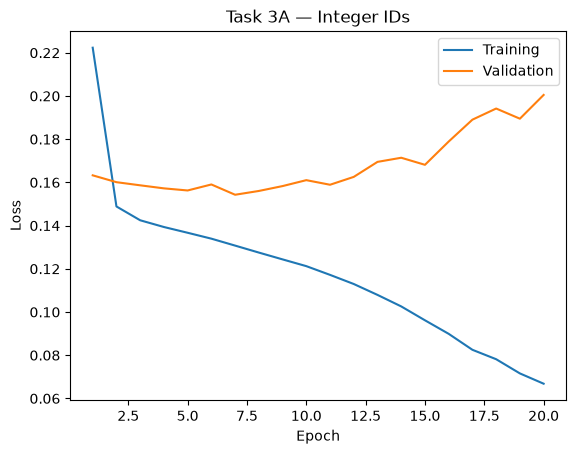

In [52]:
# TRAIN 

import time

train_losses_ids = []
val_losses_ids = []
training_seconds_ids = 0

# Move validation data once
X_val_device = X_val_ids.to(device)
y_val_device = y_val_ids.to(device)

for epoch in range(EPOCHS):
    # Training: update model weights
    model_ids.train()
    total_loss = 0
    start = time.perf_counter()

    for X_batch, y_batch in train_loader_ids:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer_ids.zero_grad()
        predictions = model_ids(X_batch)
        loss = loss_fn(predictions, y_batch)
        loss.backward()
        optimizer_ids.step()

        total_loss += loss.item() * len(y_batch)

    training_seconds_ids += time.perf_counter() - start
    train_losses_ids.append(total_loss / len(y_train_ids))

    # Validation: measure loss without updating weights
    model_ids.eval()
    with torch.no_grad():
        val_predictions = model_ids(X_val_device)
        val_loss = loss_fn(val_predictions, y_val_device)

    val_losses_ids.append(val_loss.item())

print(f"Training time: {training_seconds_ids:.2f} s")

# Compare learning curves
epochs = range(1, EPOCHS + 1)
plt.plot(epochs, train_losses_ids, label="Training")
plt.plot(epochs, val_losses_ids, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Task 3A — Integer IDs")
plt.legend()
plt.show()

              precision    recall  f1-score   support

    Goodware     0.3056    0.0902    0.1392       122
     Malware     0.9656    0.9920    0.9787      3143

    accuracy                         0.9583      3265
   macro avg     0.6356    0.5411    0.5589      3265
weighted avg     0.9410    0.9583    0.9473      3265



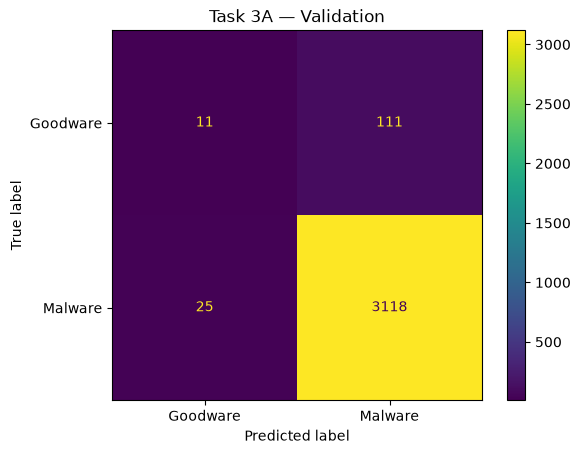

In [53]:
# EVAL
model_ids.eval()
with torch.no_grad():
    probabilities = torch.sigmoid(model_ids(X_val_device))
    predictions_ids = (probabilities > 0.5).int().cpu().numpy()

print(classification_report(
    val_split["is_malware"],
    predictions_ids,
    target_names=["Goodware", "Malware"],
    digits=4,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    val_split["is_malware"],
    predictions_ids,
    display_labels=["Goodware", "Malware"]
)
plt.title("Task 3A — Validation")
plt.show()

Task 3B

In [58]:
# Learn one vector per API, then use the shared FFNN
class EmbeddingFFNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(
            VOCAB_SIZE, EMB_DIM, padding_idx=PAD
        )
        self.ffnn = SequenceFFNN(MAX_LEN * EMB_DIM)

    def forward(self, x):
        x = self.embedding(x)  # 90 IDs -> 90 vectors
        x = x.flatten(1)       # 90 × 16 -> 1440 values
        return self.ffnn(x)


torch.manual_seed(SEED)
model_emb = EmbeddingFFNN().to(device)

# Embedding requires integer IDs, without scaling
X_train_emb = torch.tensor(ids_train, dtype=torch.long)
X_val_emb = torch.tensor(ids_val, dtype=torch.long, device=device)

# Same labels and batch size as Task 3A
train_loader_emb = DataLoader(
    TensorDataset(X_train_emb, y_train_ids),
    batch_size=BATCH_SIZE,
    shuffle=True
)

loss_fn = nn.BCEWithLogitsLoss()
optimizer_emb = torch.optim.Adam(
    model_emb.parameters(), lr=LEARNING_RATE
)

Training time: 11.67 s


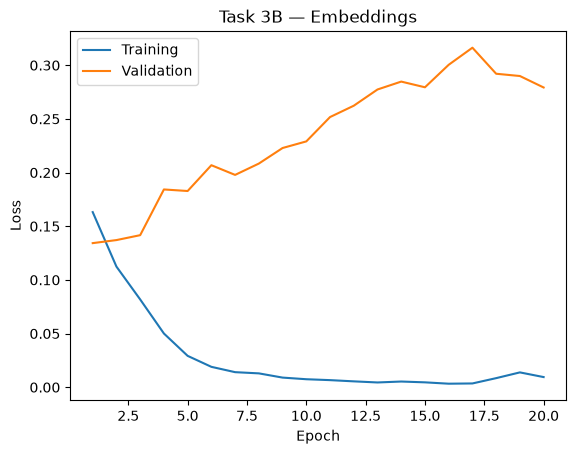

In [59]:
train_losses_emb = []
val_losses_emb = []
training_seconds_emb = 0

y_val_device = y_val_ids.to(device)

for epoch in range(EPOCHS):
    # Training: update embeddings and FFNN together
    model_emb.train()
    total_loss = 0
    start = time.perf_counter()

    for X_batch, y_batch in train_loader_emb:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer_emb.zero_grad()
        predictions = model_emb(X_batch)
        loss = loss_fn(predictions, y_batch)
        loss.backward()
        optimizer_emb.step()

        total_loss += loss.item() * len(y_batch)

    training_seconds_emb += time.perf_counter() - start
    train_losses_emb.append(total_loss / len(y_train_ids))

    # Validation: no weight updates
    model_emb.eval()
    with torch.no_grad():
        val_predictions = model_emb(X_val_emb)
        val_loss = loss_fn(val_predictions, y_val_device)

    val_losses_emb.append(val_loss.item())

print(f"Training time: {training_seconds_emb:.2f} s")

epochs = range(1, EPOCHS + 1)
plt.plot(epochs, train_losses_emb, label="Training")
plt.plot(epochs, val_losses_emb, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Task 3B — Embeddings")
plt.legend()
plt.show()

              precision    recall  f1-score   support

    Goodware     0.4667    0.2295    0.3077       122
     Malware     0.9707    0.9898    0.9802      3143

    accuracy                         0.9614      3265
   macro avg     0.7187    0.6097    0.6439      3265
weighted avg     0.9518    0.9614    0.9550      3265



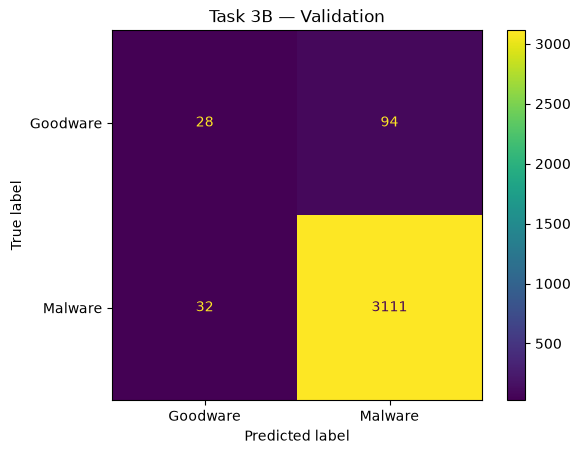

In [60]:
model_emb.eval()
with torch.no_grad():
    probabilities = torch.sigmoid(model_emb(X_val_emb))
    predictions_emb = (probabilities > THRESHOLD).int().cpu().numpy()

print(classification_report(
    val_split["is_malware"],
    predictions_emb,
    target_names=["Goodware", "Malware"],
    digits=4,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    val_split["is_malware"],
    predictions_emb,
    display_labels=["Goodware", "Malware"]
)
plt.title("Task 3B — Validation")
plt.show()

API distinte: 258 - MAX_LEN: 90
[Embeddings] Epoca 1/20 - loss: 0.1636
[Embeddings] Epoca 2/20 - loss: 0.1155
[Embeddings] Epoca 3/20 - loss: 0.0849
[Embeddings] Epoca 4/20 - loss: 0.0530
[Embeddings] Epoca 5/20 - loss: 0.0323
[Embeddings] Epoca 6/20 - loss: 0.0208
[Embeddings] Epoca 7/20 - loss: 0.0139
[Embeddings] Epoca 8/20 - loss: 0.0129
[Embeddings] Epoca 9/20 - loss: 0.0116
[Embeddings] Epoca 10/20 - loss: 0.0075
[Embeddings] Epoca 11/20 - loss: 0.0080
[Embeddings] Epoca 12/20 - loss: 0.0084
[Embeddings] Epoca 13/20 - loss: 0.0090
[Embeddings] Epoca 14/20 - loss: 0.0071
[Embeddings] Epoca 15/20 - loss: 0.0063
[Embeddings] Epoca 16/20 - loss: 0.0069
[Embeddings] Epoca 17/20 - loss: 0.0052
[Embeddings] Epoca 18/20 - loss: 0.0041
[Embeddings] Epoca 19/20 - loss: 0.0048
[Embeddings] Epoca 20/20 - loss: 0.0053

===== Embeddings =====
              precision    recall  f1-score   support

           0     0.2330    0.1687    0.1957       243
           1     0.9681    0.9784    0.9732 

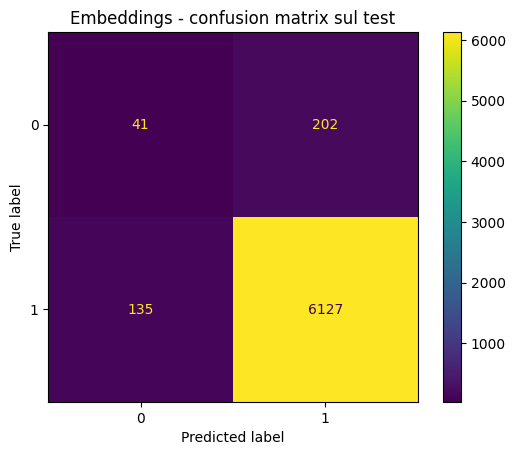

In [ ]:
### LEGACY CODE 

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEQ, LABEL = "api_call_sequence", "is_malware"
torch.manual_seed(42)

# =========================================================
# 1. DA API A ID INTERI 
# =========================================================

PAD, UNK = 0, 1   # 0 = padding, 1 = API mai vista nel train

# Vocabolario costruito SOLO sul train: ogni API riceve un ID da 2 in su
api_list = sorted({api for seq in train_pd[SEQ] for api in seq})
vocab = {api: i + 2 for i, api in enumerate(api_list)}
VOCAB_SIZE = len(vocab) + 2   # +2 per PAD e UNK

# Lunghezza fissa = sequenza più lunga del train
MAX_LEN = train_pd[SEQ].apply(len).max()
print("API distinte:", len(vocab), "- MAX_LEN:", MAX_LEN)

def encode(seq):
    ids = [vocab.get(api, UNK) for api in seq[:MAX_LEN]]   # tronca tenendo l'inizio
    return ids + [PAD] * (MAX_LEN - len(ids))               # padding fino a MAX_LEN

ids_train = np.array([encode(s) for s in train_pd[SEQ]])   # forma: (n_sequenze, MAX_LEN)
ids_test  = np.array([encode(s) for s in test_pd[SEQ]])

y_train = torch.tensor(train_pd[LABEL].values, dtype=torch.float32)
y_test  = test_pd[LABEL].values

# =========================================================
# 2. ARCHITETTURA COMUNE 
# =========================================================

class FFNN(nn.Module):
    def __init__(self, in_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 64), nn.ReLU(),   # strato nascosto 1
            nn.Linear(64, 32),     nn.ReLU(),   # strato nascosto 2
            nn.Linear(32, 1),                   # output: 1 logit
        )
    def forward(self, x):
        return self.net(x).squeeze(1)

# =========================================================
# 3. TRAINING E VALUTAZIONE 
# =========================================================

def train_and_evaluate(model, X_train, X_test, name, epochs=20):
    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64, shuffle=True)

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        print(f"[{name}] Epoca {epoch + 1}/{epochs} - loss: {total_loss / len(loader):.4f}")

    model.eval()
    with torch.no_grad():
        y_pred = (torch.sigmoid(model(X_test)) > 0.5).int().numpy()

    print(f"\n===== {name} =====")
    print(classification_report(y_test, y_pred, digits=4))
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot()
    plt.title(f"{name} - confusion matrix sul test")
    plt.show()
    return y_pred

# =========================================================
# 4. ENCODING (b): EMBEDDING ADDESTRABILI
# =========================================================

EMB_DIM = 16

class EmbeddingFFNN(nn.Module):
    def __init__(self):
        super().__init__()
        # Tabella addestrabile: ogni ID -> vettore di 16 numeri (il PAD resta a zero)
        self.emb = nn.Embedding(VOCAB_SIZE, EMB_DIM, padding_idx=PAD)
        # Stessa architettura di (a): cambia solo la dimensione dell'input
        self.ffnn = FFNN(in_dim=MAX_LEN * EMB_DIM)

    def forward(self, x):
        x = self.emb(x)         # (batch, MAX_LEN) -> (batch, MAX_LEN, 16)
        x = x.flatten(1)        # -> (batch, MAX_LEN * 16): un unico vettore
        return self.ffnn(x)

# L'embedding vuole ID interi (long), NON scalati
Xb_train = torch.tensor(ids_train, dtype=torch.long)
Xb_test  = torch.tensor(ids_test,  dtype=torch.long)

model_b = EmbeddingFFNN()
y_pred_emb = train_and_evaluate(model_b, Xb_train, Xb_test, "Embeddings")

#Entrambi i modelli raggiungono un’accuracy di circa il 95%, valore vicino a quello di un classificatore che predice sempre la classe maggioritaria e quindi poco informativo a causa del forte sbilanciamento. La macro F1 mostra invece prestazioni limitate: 0.52 per gli ID interi e 0.58 per gli embedding. Gli embedding migliorano soprattutto la recall sulla classe minoritaria, perché imparano una rappresentazione delle API in cui chiamate simili hanno vettori simili, mentre gli ID interi impongono un ordinamento arbitrario. In entrambi i casi l’assenza di una gestione dello sbilanciamento porta il modello a favorire la classe maggioritaria.